# Project 3: Resume Parser & Candidate Matcher

**Module:** Natural Language Processing (CDAC)

### Overview
This project implements an automated recruitment pipeline that extracts key entities from unstructured candidate resumes and calculates matching percentages against target job descriptions.

### Architecture & Techniques
1. **Named Entity Recognition (NER):** Uses spaCy `en_core_web_sm` (~12 MB lightweight model) to detect person names (`PERSON`) and organizations (`ORG`).
2. **Regular Expressions:** Extracts validated email addresses and telephone numbers.
3. **Vocabulary & Boundary Matching:** Detects technical skills using `SKILL_ALIASES` and regex lookaround boundaries to prevent false positives (e.g. distinguishing `java` from `javascript`).
4. **Jaccard / Overlap Scoring:** Computes `matched_skills / required_skills * 100` to rank candidates.

In [1]:
import os
import re
import json
import pandas as pd
import matplotlib.pyplot as plt
import spacy

nlp = spacy.load("en_core_web_sm")
print("spaCy pipeline successfully loaded:", nlp.meta["name"], "v" + nlp.meta["version"])
print("Pipeline components:", nlp.pipe_names)

spaCy pipeline successfully loaded: core_web_sm v3.8.0
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


### Step 1: Input Job Description and Candidate Resumes
We load the target job description and the three reference candidate profiles.

In [2]:
job_description = """We are looking for a Python developer with experience in machine learning,
natural language processing, SQL, pandas, and scikit-learn. Experience with FastAPI and Docker is an advantage."""

sample_candidates = [
    {
        "candidate_id": "Candidate_A",
        "resume_text": """Ananya Rao
Email: ananya.rao@example.com
Phone: +91 98765 43210
Education: B.Tech Computer Science
Skills: Python, machine learning, natural language processing, SQL, pandas, scikit-learn, FastAPI.
Experience: Data Science Intern at ABC Technologies."""
    },
    {
        "candidate_id": "Candidate_B",
        "resume_text": """Rahul Kumar
Email: rahul.kumar@example.com
Phone: 9876543210
Education: B.E. Information Science
Skills: Python, SQL, pandas, Docker, Java, data analysis.
Experience: Software Engineer at Bright Systems."""
    },
    {
        "candidate_id": "Candidate_C",
        "resume_text": """Meera Nair
Email: meera.nair@example.com
Phone: +91-9988776655
Education: M.Sc. Data Science
Skills: Python, machine learning, scikit-learn, natural language processing, FastAPI, Docker.
Experience: Research Assistant at Data Research Lab."""
    }
]

print("Target Job Description:")
print(job_description)
print(f"\nLoaded {len(sample_candidates)} candidate profiles.")

Target Job Description:
We are looking for a Python developer with experience in machine learning,
natural language processing, SQL, pandas, and scikit-learn. Experience with FastAPI and Docker is an advantage.

Loaded 3 candidate profiles.


### Step 2: Skill Extraction Engine
Using regular expressions with negative lookahead/lookbehind word boundaries to extract canonical skills.

In [3]:
SKILL_ALIASES = {
    "python": ["python"],
    "java": ["java"],
    "c++": ["c++"],
    "c#": ["c#"],
    "sql": ["sql"],
    "machine learning": ["machine learning", "ml"],
    "deep learning": ["deep learning"],
    "natural language processing": ["natural language processing", "nlp"],
    "computer vision": ["computer vision"],
    "data analysis": ["data analysis", "data analytics"],
    "pandas": ["pandas"],
    "numpy": ["numpy"],
    "scikit-learn": ["scikit-learn", "sklearn"],
    "pytorch": ["pytorch", "torch"],
    "tensorflow": ["tensorflow"],
    "spacy": ["spacy", "spaCy"],
    "transformers": ["transformers", "hugging face"],
    "postgresql": ["postgresql", "postgres"],
    "mysql": ["mysql"],
    "mongodb": ["mongodb"],
    "fastapi": ["fastapi"],
    "flask": ["flask"],
    "django": ["django"],
    "docker": ["docker"],
    "aws": ["aws", "amazon web services"],
    "azure": ["azure", "microsoft azure"],
}

EDUCATION_TERMS = [
    "b.e.", "b.e", "b.tech", "btech", "m.e.", "m.e", "m.tech", "mtech",
    "b.sc", "bsc", "m.sc", "msc", "mba", "ph.d", "phd", "bachelor", "master"
]

def contains_phrase(text_lower: str, phrase: str) -> bool:
    escaped = re.escape(phrase.lower())
    pattern = rf"(?<![a-z0-9]){escaped}(?![a-z0-9])"
    return re.search(pattern, text_lower) is not None

def extract_skills(text: str):
    text_lower = text.lower()
    found = []
    for canonical_skill, aliases in SKILL_ALIASES.items():
        if any(contains_phrase(text_lower, alias) for alias in aliases):
            found.append(canonical_skill)
    return sorted(found)

required_skills = extract_skills(job_description)
print(f"Detected Required Skills ({len(required_skills)}):")
for s in required_skills:
    print(f"  - {s}")

Detected Required Skills (8):
  - docker
  - fastapi
  - machine learning
  - natural language processing
  - pandas
  - python
  - scikit-learn
  - sql


### Step 3: Information Extraction via spaCy NER and Regex
Extracting candidate name, email, phone number, education, and past organizations.

In [4]:
def parse_resume(resume_text: str):
    doc = nlp(resume_text)
    names = []
    orgs = []
    for ent in doc.ents:
        if ent.label_ == "PERSON":
            clean_name = re.split(r"[\n\r]|Email|Phone", ent.text, flags=re.IGNORECASE)[0].strip()
            if clean_name and clean_name not in names:
                names.append(clean_name)
        elif ent.label_ == "ORG" and ent.text not in orgs:
            orgs.append(ent.text.strip())

    emails = sorted(set(re.findall(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", resume_text)))
    phones = sorted(set(re.findall(r"(?<!\w)(?:\+?\d[\d .()\-]{7,}\d)(?!\w)", resume_text)))
    phones = [re.sub(r"\s+", " ", p).strip() for p in phones]

    lower_text = resume_text.lower()
    education = [term for term in EDUCATION_TERMS if contains_phrase(lower_text, term)]

    return {
        "candidate_name": names[0] if names else "Unknown",
        "all_names": names,
        "emails": emails,
        "phones": phones,
        "education": education,
        "organizations": orgs,
        "skills": extract_skills(resume_text)
    }

# Demonstration on Candidate_A
demo_parsed = parse_resume(sample_candidates[0]["resume_text"])
print("Parsed Demonstration (Candidate A):")
print(json.dumps(demo_parsed, indent=2))

Parsed Demonstration (Candidate A):
{
  "candidate_name": "Ananya Rao",
  "all_names": [
    "Ananya Rao"
  ],
  "emails": [
    "ananya.rao@example.com"
  ],
  "phones": [
    "+91 98765 43210"
  ],
  "education": [
    "b.tech"
  ],
  "organizations": [
    "B.Tech Computer Science\nSkills: Python",
    "SQL",
    "pandas",
    "ABC Technologies"
  ],
  "skills": [
    "fastapi",
    "machine learning",
    "natural language processing",
    "pandas",
    "python",
    "scikit-learn",
    "sql"
  ]
}


### Step 4: Candidate Ranking & Match Scoring
Compute overlap percentages between candidate skills and required skills.

In [5]:
ranking_records = []
for c in sample_candidates:
    parsed = parse_resume(c["resume_text"])
    cand_skills = set(parsed["skills"])
    req_skills = set(required_skills)
    matched = sorted(list(cand_skills & req_skills))
    missing = sorted(list(req_skills - cand_skills))
    score = len(matched) / len(req_skills) if req_skills else 0.0

    ranking_records.append({
        "Candidate ID": c["candidate_id"],
        "Name": parsed["candidate_name"],
        "Match Score (%)": round(score * 100, 1),
        "Score": score,
        "Matched Count": f"{len(matched)} / {len(req_skills)}",
        "Matched Skills": ", ".join(matched),
        "Missing Skills": ", ".join(missing),
        "Email": parsed["emails"][0] if parsed["emails"] else "N/A",
        "Phone": parsed["phones"][0] if parsed["phones"] else "N/A",
        "Education": ", ".join(parsed["education"])
    })

df_ranking = pd.DataFrame(ranking_records).sort_values(by="Score", ascending=False).reset_index(drop=True)
df_ranking.index += 1
df_ranking.index.name = "Rank"
display(df_ranking[["Candidate ID", "Name", "Match Score (%)", "Matched Count", "Matched Skills", "Missing Skills"]])

,Candidate ID,Name,Match Score (%),Matched Count,Matched Skills,Missing Skills
Rank,,,,,,
1,Candidate_A,Ananya Rao,87.5,7 / 8,"fastapi, machine learning, natural language pr...",docker
2,Candidate_C,Meera Nair,75.0,6 / 8,"docker, fastapi, machine learning, natural lan...","pandas, sql"
3,Candidate_B,Rahul Kumar,50.0,4 / 8,"docker, pandas, python, sql","fastapi, machine learning, natural language pr..."


### Step 5: Visualizing Match Distribution
Plotting the candidate match percentages against the 8 required skills.

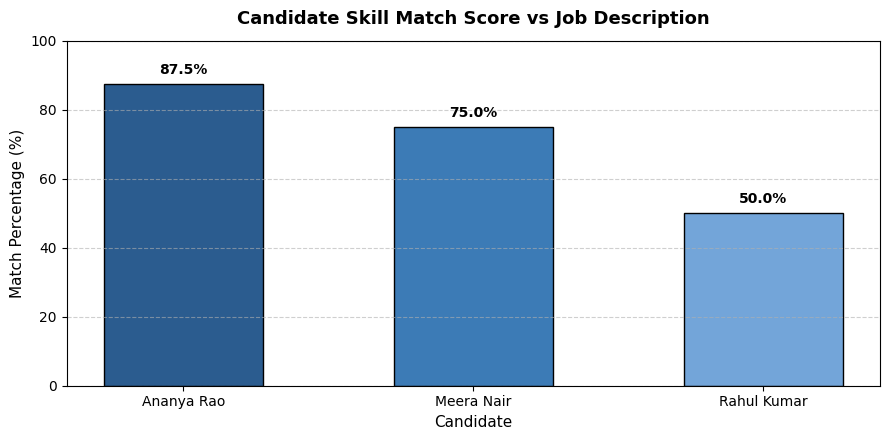

In [6]:
plt.figure(figsize=(9, 4.5))
colors = ["#2b5c8f", "#3c7bb6", "#73a5d9"]
bars = plt.bar(df_ranking["Name"], df_ranking["Match Score (%)"], color=colors, width=0.55, edgecolor="black")

plt.title("Candidate Skill Match Score vs Job Description", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Match Percentage (%)", fontsize=11)
plt.xlabel("Candidate", fontsize=11)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f}%", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

### Step 6: Summary & Viva Preparation
1. **Why use spaCy instead of pure regex for names?** Natural names vary widely and lack fixed formats. spaCy's statistical transition-based NER model (`en_core_web_sm`) recognizes context and POS tags to label `PERSON` spans accurately.
2. **Why use regex lookaround for skills?** Single-word technical skills like `C`, `R`, or `Java` can be substrings of other common words (`script`, `javascript`, `developer`). Lookaround `(?<![a-z0-9])` ensures token boundaries without requiring extra whitespace tokens.
3. **What is the mathematical formulation of the match score?**
$$\text{Match Score} = \frac{|S_{\text{candidate}} \cap S_{\text{job}}|}{|S_{\text{job}}|}$$
4. **Model Footprint:** spaCy `en_core_web_sm` is approximately 12 MB, satisfying strict lightweight deployment requirements.